# Garbage Classification - EDA

Mục tiêu: xem qua dữ liệu trước khi tiền xử lý và đưa vào CNN.
- Có bao nhiêu ảnh, có ảnh nào bị lỗi không
- Các lớp có bị lệch nhau không
- Kích thước, định dạng ảnh có giống nhau không
- Có ảnh trùng nhau không

Notebook này chỉ xem và thống kê, không xóa hay sửa ảnh. Việc làm sạch và chia tập nằm ở bước tiền xử lý.

Dữ liệu: [Garbage Classification (12 classes) - Kaggle](https://www.kaggle.com/datasets/mostafaabla/garbage-classification)

## 0. Import và đường dẫn dữ liệu

In [1]:
from pathlib import Path
import hashlib

import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

SEED = 42

CLASSES = [
    'battery', 'biological', 'brown-glass', 'cardboard', 'clothes',
    'green-glass', 'metal', 'paper', 'plastic', 'shoes',
    'trash', 'white-glass',
]

# tìm thư mục ảnh, chạy từ thư mục nào trong project cũng được
DATA_DIR = None
for base in [Path.cwd(), *Path.cwd().parents]:
    for relative in ['data/raw/garbage_classification',
                     'deep_learning-waste_classification/data/raw/garbage_classification']:
        if (base / relative).is_dir() and DATA_DIR is None:
            DATA_DIR = (base / relative).resolve()

if DATA_DIR is None:
    raise FileNotFoundError('Không tìm thấy thư mục garbage_classification, kiểm tra lại đường dẫn')

print('Thư mục dữ liệu:', DATA_DIR)

Thư mục dữ liệu: C:\Users\Lenovo\Documents\Deep Learning\Mid-term Project\deep_learning-waste_classification\data\raw\garbage_classification


## 1. Kiểm kê ảnh

Mở từng ảnh để lấy kích thước, định dạng, mode màu và dung lượng. Ảnh nào mở không được sẽ ghi lại lỗi để loại ở bước tiền xử lý.

In [2]:
records = []
for class_dir in sorted(DATA_DIR.iterdir()):
    if not class_dir.is_dir():
        continue
    for path in class_dir.iterdir():
        if path.suffix.lower() not in ['.jpg', '.jpeg', '.png']:
            continue
        info = {
            'filepath': path.relative_to(DATA_DIR).as_posix(),
            'label': class_dir.name,
            'width': None, 'height': None, 'format': None, 'mode': None,
            'size_kb': path.stat().st_size / 1024,
            'error': None,
        }
        try:
            with Image.open(path) as im:
                im.load()
                info['width'], info['height'] = im.size
                info['format'] = im.format
                info['mode'] = im.mode
        except Exception as e:
            info['error'] = str(e)
        records.append(info)

df = pd.DataFrame(records)
valid = df[df['error'].isna()].copy()

print('Tổng số ảnh:', len(df))
print('Đọc được:', len(valid))
print('Lỗi:', len(df) - len(valid))
print('Số lớp:', df['label'].nunique())

errors = df[df['error'].notna()]
if len(errors) > 0:
    display(errors[['filepath', 'label', 'error']])

Tổng số ảnh: 15515
Đọc được: 15515
Lỗi: 0
Số lớp: 12


## 2. Phân bố lớp

Đếm số ảnh mỗi lớp. Nếu các lớp lệch nhiều thì khi train cần dùng class weight, và khi đánh giá nên xem thêm precision/recall/F1 từng lớp chứ không chỉ accuracy.

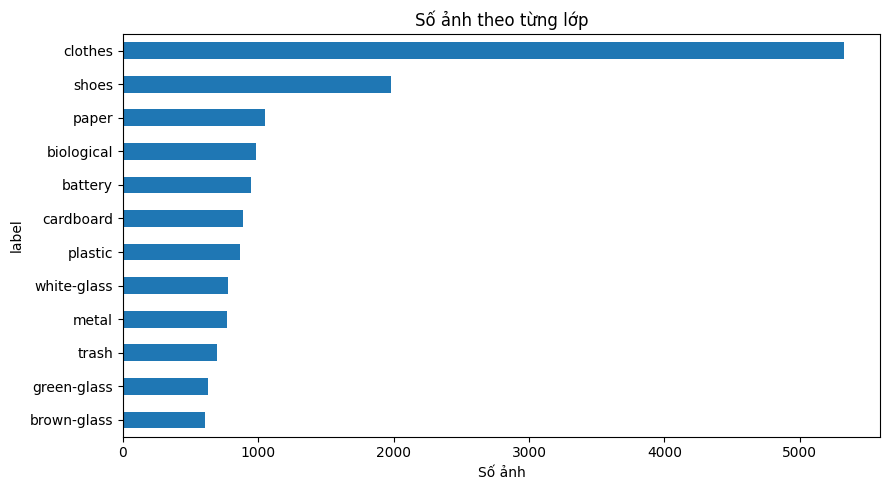

Lớp nhiều ảnh nhất: clothes 5325
Lớp ít ảnh nhất: brown-glass 607
Tỉ lệ lệch (max/min): 8.77


In [3]:
counts = valid['label'].value_counts().reindex(CLASSES, fill_value=0)

plt.figure(figsize=(9, 5))
counts.sort_values().plot(kind='barh')
plt.xlabel('Số ảnh')
plt.title('Số ảnh theo từng lớp')
plt.tight_layout()
plt.show()

imbalance_ratio = counts.max() / counts.min()
print('Lớp nhiều ảnh nhất:', counts.idxmax(), counts.max())
print('Lớp ít ảnh nhất:', counts.idxmin(), counts.min())
print('Tỉ lệ lệch (max/min):', round(imbalance_ratio, 2))

## 3. Xem ảnh mẫu

Lấy ngẫu nhiên 4 ảnh mỗi lớp để xem bằng mắt: vật có rõ không, nền ra sao, có ảnh nào trông bị gán nhầm lớp không.

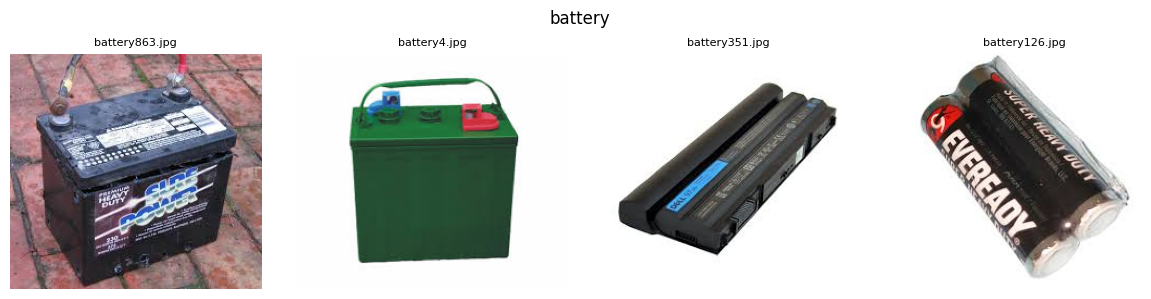

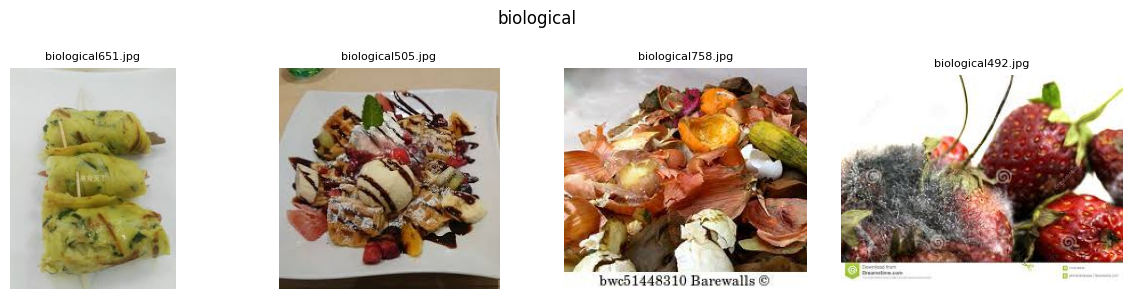

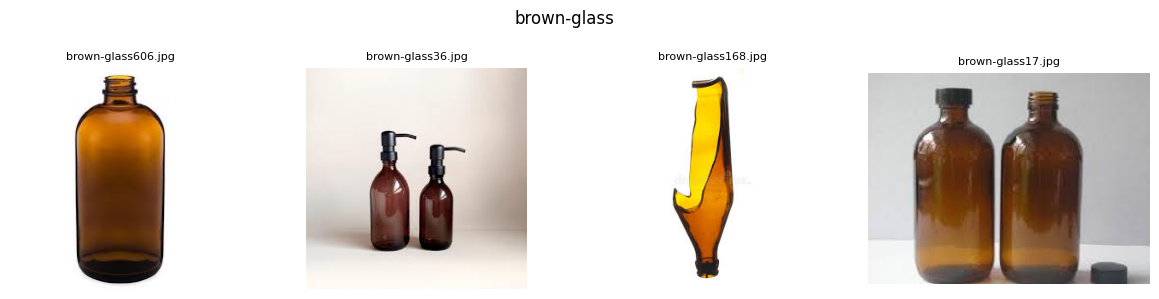

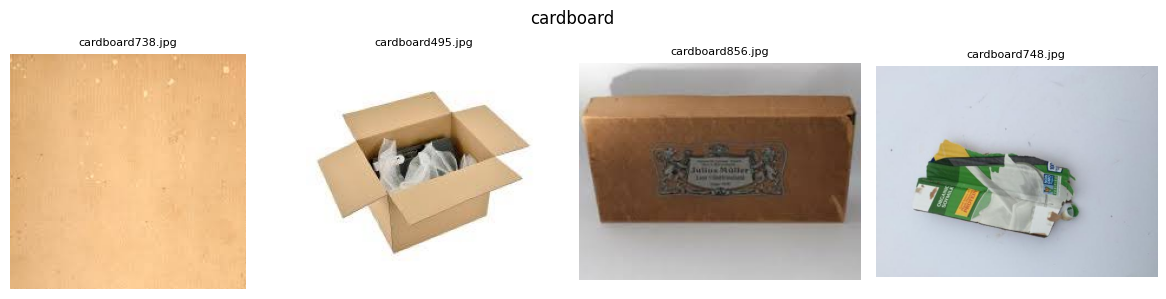

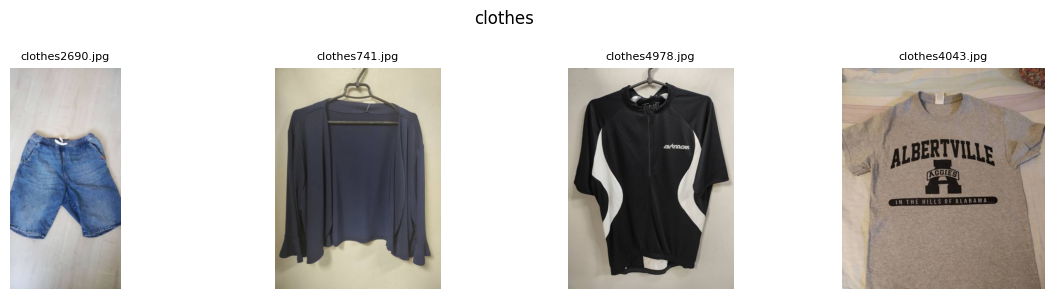

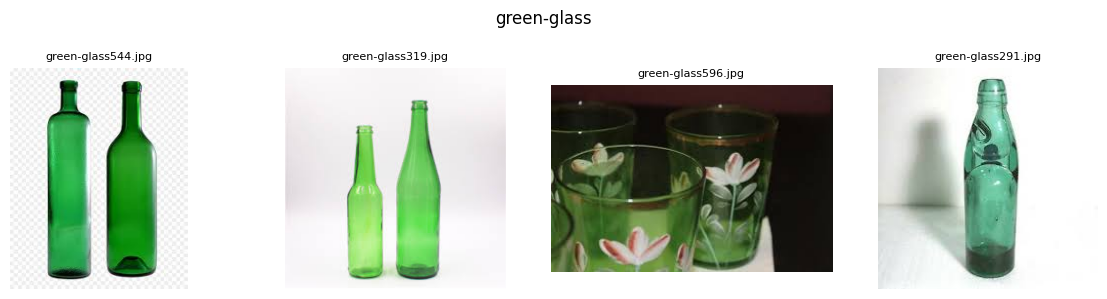

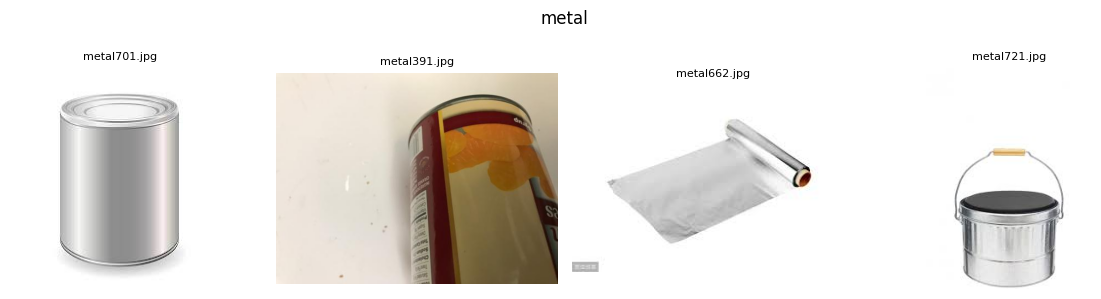

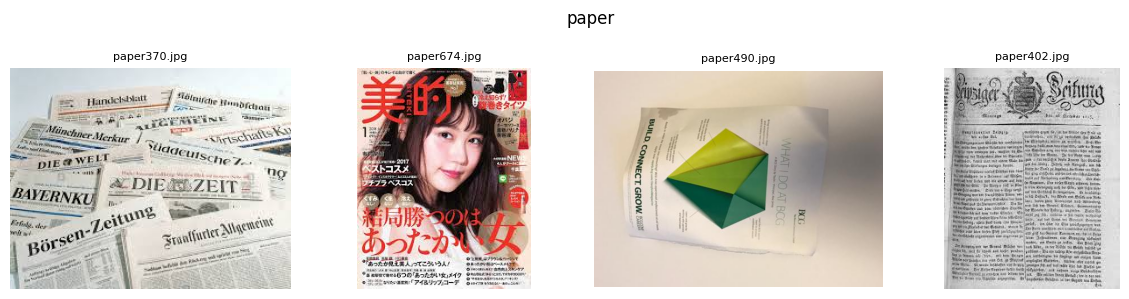

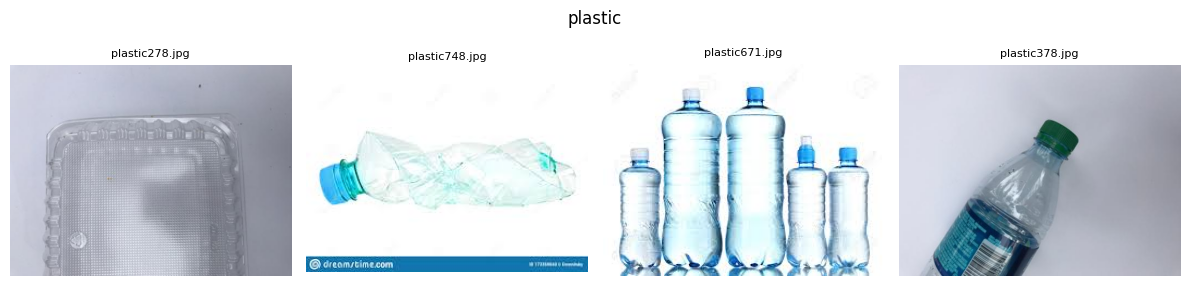

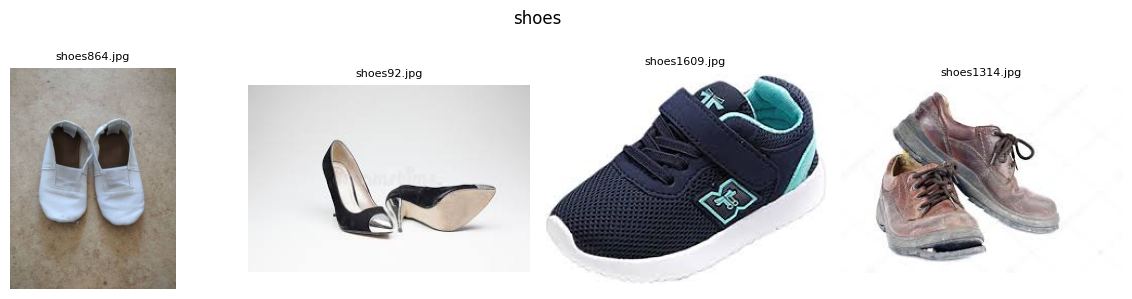

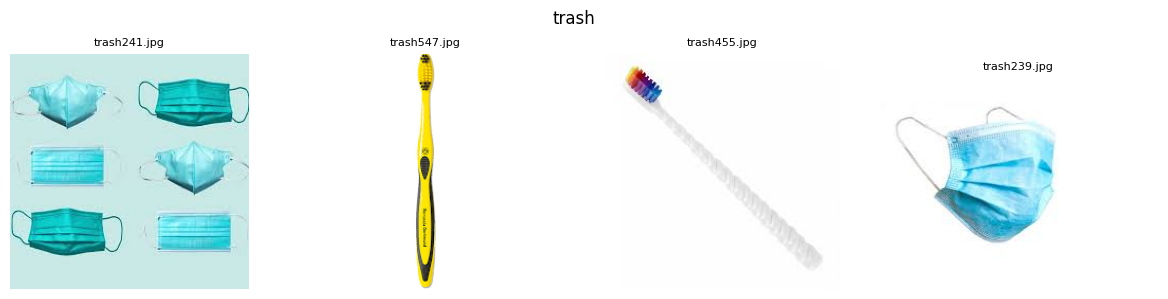

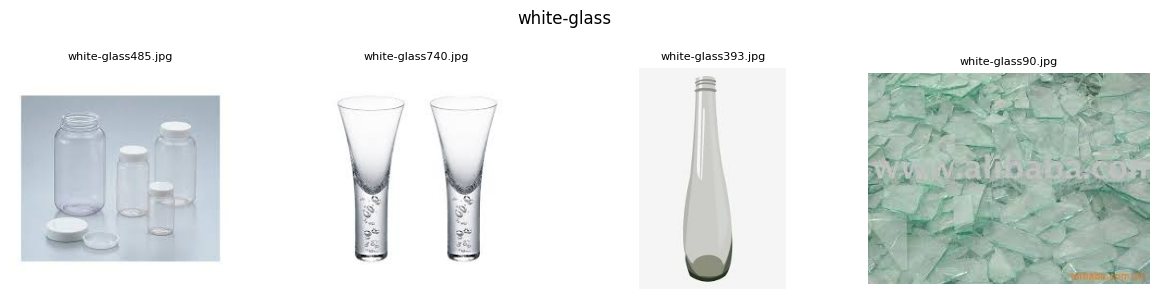

In [4]:
for label in CLASSES:
    sample = valid[valid['label'] == label].sample(4, random_state=SEED)
    plt.figure(figsize=(12, 3))
    for i, filepath in enumerate(sample['filepath']):
        plt.subplot(1, 4, i + 1)
        with Image.open(DATA_DIR / filepath) as im:
            plt.imshow(im.convert('RGB'))
        plt.title(Path(filepath).name, fontsize=8)
        plt.axis('off')
    plt.suptitle(label)
    plt.tight_layout()
    plt.show()

## 4. Kích thước và định dạng

Nếu kích thước ảnh không đồng nhất thì bắt buộc phải resize. Nếu có nhiều mode màu (RGB, L, RGBA...) thì phải đưa về RGB trước khi vào model.

Số kích thước khác nhau: 892
Định dạng ảnh: ['JPEG', 'PNG']
Mode màu: ['P', 'RGB']


,width,height,size_kb
count,15515.000000,15515.000000,15515.000000
mean,349.822301,351.705833,15.767770
std,117.548544,149.418487,12.094970
min,51.000000,100.000000,1.047852
25%,234.000000,224.000000,5.804688
50%,400.000000,384.000000,12.764648
75%,400.000000,533.000000,22.713867
max,888.000000,936.000000,85.656250


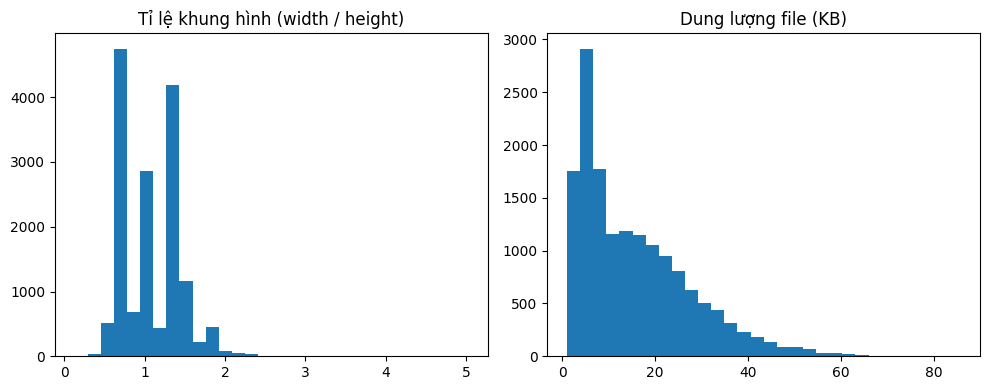

In [5]:
print('Số kích thước khác nhau:', valid[['width', 'height']].drop_duplicates().shape[0])
print('Định dạng ảnh:', sorted(valid['format'].unique()))
print('Mode màu:', sorted(valid['mode'].unique()))

display(valid[['width', 'height', 'size_kb']].describe())

plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
plt.hist(valid['width'] / valid['height'], bins=30)
plt.title('Tỉ lệ khung hình (width / height)')
plt.subplot(1, 2, 2)
plt.hist(valid['size_kb'], bins=30)
plt.title('Dung lượng file (KB)')
plt.tight_layout()
plt.show()

## 5. Ảnh trùng lặp

Chỉ kiểm tra ảnh trùng hoàn toàn (giống nhau từng byte) bằng SHA-256. Ảnh trùng mà rơi vào cả train và test thì kết quả đánh giá sẽ bị sai (data leakage).

Cần chú ý nhóm trùng nhưng khác nhãn: cùng một ảnh nhưng nằm ở 2 lớp khác nhau, nghĩa là ít nhất một nhãn bị gán sai.

In [6]:
valid['file_hash'] = [hashlib.sha256((DATA_DIR / p).read_bytes()).hexdigest() for p in valid['filepath']]

dup = valid[valid.duplicated('file_hash', keep=False)]

rows = []
for file_hash, group in dup.groupby('file_hash'):
    rows.append({
        'group_id': 'group_' + str(len(rows) + 1).zfill(3),
        'n_images': len(group),
        'labels': sorted(group['label'].unique()),
        'cross_label': group['label'].nunique() > 1,
        'files': group['filepath'].tolist(),
    })
dup_table = pd.DataFrame(rows, columns=['group_id', 'n_images', 'labels', 'cross_label', 'files'])

n_groups = len(dup_table)
n_extra = len(dup) - n_groups

print('Số nhóm ảnh trùng:', n_groups)
print('Số ảnh dư nếu mỗi nhóm chỉ giữ 1 ảnh:', n_extra)
print('Số nhóm trùng khác nhãn:', dup_table['cross_label'].sum())

display(dup_table)

Số nhóm ảnh trùng: 18
Số ảnh dư nếu mỗi nhóm chỉ giữ 1 ảnh: 19
Số nhóm trùng khác nhãn: 3


,group_id,n_images,labels,cross_label,files
0,group_001,2,[green-glass],False,"[green-glass/green-glass285.jpg, green-glass/g..."
1,group_002,2,[green-glass],False,"[green-glass/green-glass403.jpg, green-glass/g..."
2,group_003,2,[green-glass],False,"[green-glass/green-glass476.jpg, green-glass/g..."
3,group_004,2,[green-glass],False,"[green-glass/green-glass336.jpg, green-glass/g..."
4,group_005,2,[green-glass],False,"[green-glass/green-glass449.jpg, green-glass/g..."
5,group_006,2,[clothes],False,"[clothes/clothes2051.jpg, clothes/clothes5234...."
6,group_007,2,[green-glass],False,"[green-glass/green-glass388.jpg, green-glass/g..."
7,group_008,2,[green-glass],False,"[green-glass/green-glass424.jpg, green-glass/g..."
8,group_009,2,[green-glass],False,"[green-glass/green-glass471.jpg, green-glass/g..."
9,group_010,2,[green-glass],False,"[green-glass/green-glass231.jpg, green-glass/g..."


Xem ảnh của từng nhóm để xác nhận bằng mắt. Nhóm khác nhãn xem hết, nhóm cùng nhãn chỉ xem 5 nhóm đầu.

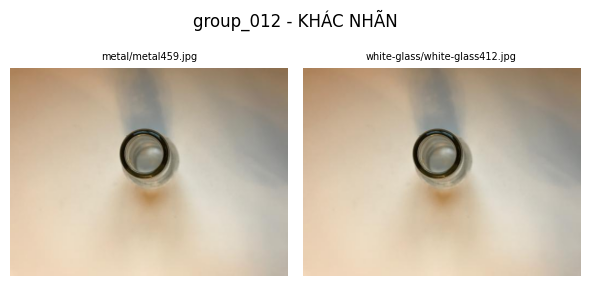

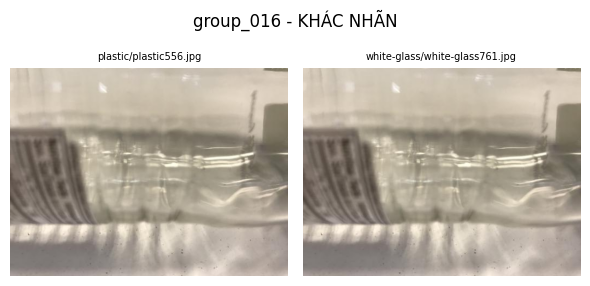

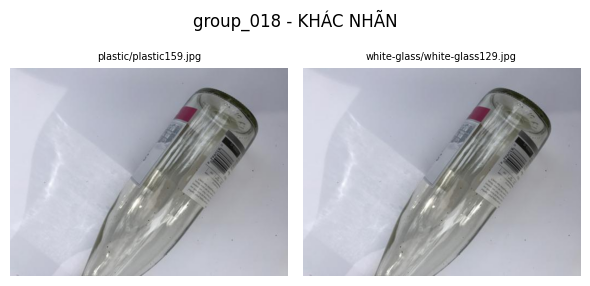

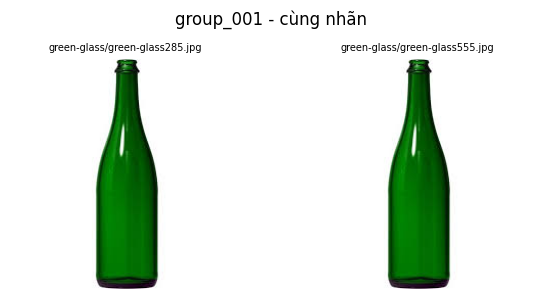

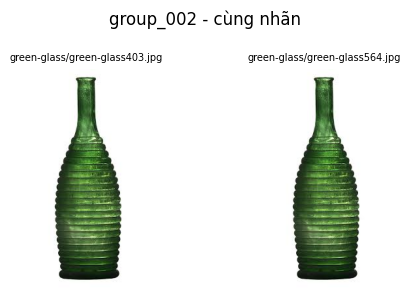

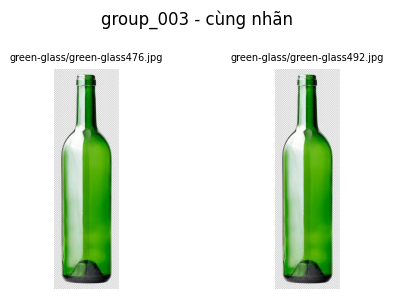

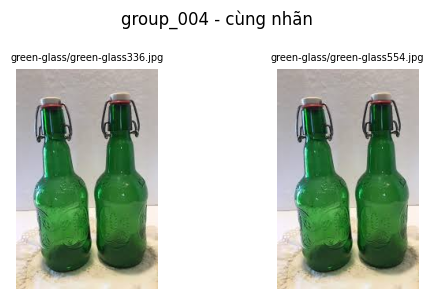

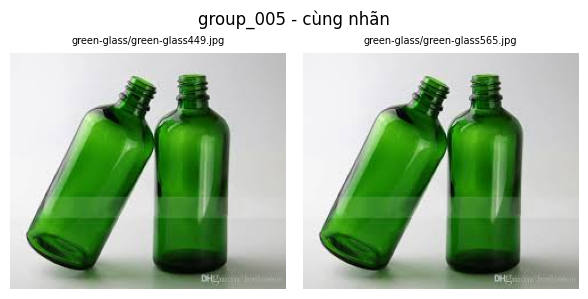

In [7]:
def show_group(row):
    files = row['files'][:6]
    plt.figure(figsize=(3 * len(files), 3))
    for i, filepath in enumerate(files):
        plt.subplot(1, len(files), i + 1)
        with Image.open(DATA_DIR / filepath) as im:
            plt.imshow(im.convert('RGB'))
        plt.title(filepath, fontsize=7)
        plt.axis('off')
    plt.suptitle(row['group_id'] + (' - KHÁC NHÃN' if row['cross_label'] else ' - cùng nhãn'))
    plt.tight_layout()
    plt.show()

for _, row in dup_table[dup_table['cross_label']].iterrows():
    show_group(row)

for _, row in dup_table[~dup_table['cross_label']].head(5).iterrows():
    show_group(row)

## 6. Tổng kết

In [8]:
print('Tổng ảnh:', len(df), '| đọc được:', len(valid), '| lỗi:', len(df) - len(valid))
print('Số lớp:', len(CLASSES), '| lệch lớp (max/min):', round(imbalance_ratio, 2))
print('Số kích thước khác nhau:', valid[['width', 'height']].drop_duplicates().shape[0])
print('Định dạng:', sorted(valid['format'].unique()), '| mode màu:', sorted(valid['mode'].unique()))
print('Số nhóm ảnh trùng:', n_groups, '| trùng khác nhãn:', dup_table['cross_label'].sum())

Tổng ảnh: 15515 | đọc được: 15515 | lỗi: 0
Số lớp: 12 | lệch lớp (max/min): 8.77
Số kích thước khác nhau: 892
Định dạng: ['JPEG', 'PNG'] | mode màu: ['P', 'RGB']
Số nhóm ảnh trùng: 18 | trùng khác nhãn: 3
